In [ ]:
!pip install xgboost pandas numpy scikit-learn matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.7/131.7 MB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 293.6/293.6 MB 1.3 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pickle
import matplotlib.pyplot as plt

# Load the dataset (Ensure you have uploaded 'indian_placement_dataset.csv' to Colab)
df = pd.read_csv('indian_placement_dataset.csv')

print(f"Dataset Loaded: {df.shape[0]} rows, {df.shape[1]} features")
df.head()

Dataset Loaded: 20000 rows, 22 features


,CGPA,ActiveBacklogs,TotalKTs,QuantitativeScore,LogicalReasoningScore,VerbalScore,CodingScore,ProjectCount,ProjectComplexity,InternshipCount,...,CommunicationScore,ConfidenceScore,TeamworkScore,ExtracurricularActivities,WorkshopCount,CertificationQuality,PlacementTrainingAttendance,PlacementTrainingQuality,MockInterviewsGiven,PlacementStatus
0,8.78,0,1,40,29,13,7,3,1,2,...,2,4,5,4,6,3,2,3,4,1
1,5.87,2,6,21,18,8,4,1,1,0,...,2,2,3,0,0,4,2,1,2,0
2,6.09,1,3,28,14,7,10,3,2,0,...,4,3,3,3,1,1,1,2,2,0
3,7.31,0,2,16,21,10,4,2,3,1,...,2,4,4,1,3,1,1,2,1,0
4,5.74,2,7,6,7,5,0,1,3,1,...,1,2,2,2,0,2,0,0,0,0


In [ ]:
# Separate Features (X) and Target (y)
X = df.drop('PlacementStatus', axis=1)
y = df['PlacementStatus']

# Stratified Split (80% Training, 20% Testing)
# 'stratify=y' is the key to preventing bias in class distribution
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Data split successfully.")
print(f"Training set size: {X_train.shape[0]}")
print(f"Testing set size: {X_test.shape[0]}")

Data split successfully.
Training set size: 16000
Testing set size: 4000


In [ ]:
# Initialize XGBoost Classifier
model = xgb.XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss'
)

# Train the model
model.fit(X_train, y_train)
print("Model training complete.")

Model training complete.


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [17:37:50] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Final Model Accuracy: 90.20%

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.92      0.92      2388
           1       0.88      0.88      0.88      1612

    accuracy                           0.90      4000
   macro avg       0.90      0.90      0.90      4000
weighted avg       0.90      0.90      0.90      4000



<Figure size 1000x600 with 0 Axes>

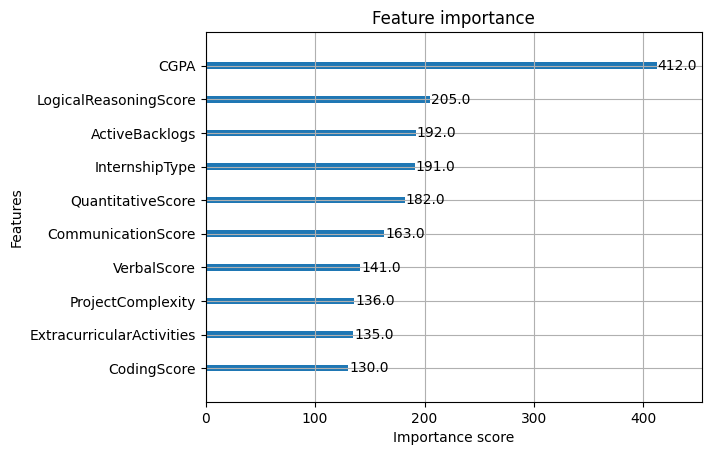

In [ ]:
# Predictions
y_pred = model.predict(X_test)

# Accuracy and Detailed Report
accuracy = accuracy_score(y_test, y_pred)
print(f"Final Model Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Feature Importance
plt.figure(figsize=(10,6))
xgb.plot_importance(model, importance_type='weight', max_num_features=10)
plt.show()

In [ ]:
# Save the model to a pickle file
filename = 'placement_model.pkl'
pickle.dump(model, open(filename, 'wb'))
print(f"Model saved as {filename}")

# Download instruction for Colab
from google.colab import files
files.download(filename)

Model saved as placement_model.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pickle
import pandas as pd

# Load the model from the local directory
model = pickle.load(open('placement_model.pkl', 'rb'))

# Example: Create a single student profile for prediction (Match the 21 feature order)
# Order: CGPA, ActiveBacklogs, TotalKTs, Quant, Logical, Verbal, Coding, etc...
new_student = pd.DataFrame([[
    8.5, 0, 0,  # Academics
    35, 25, 15, 8,  # Aptitude/Coding
    3, 4,  # Projects
    1, 3, 2,  # Internships
    4, 4, 4,  # Soft Skills
    5,  # Extracurricular
    3, 4,  # Certifications
    3, 4, 4  # Placement Training
]], columns=[
    'CGPA','ActiveBacklogs','TotalKTs','QuantitativeScore','LogicalReasoningScore',
    'VerbalScore','CodingScore','ProjectCount','ProjectComplexity','InternshipCount',
    'InternshipType','InternshipDuration','CommunicationScore','ConfidenceScore',
    'TeamworkScore','ExtracurricularActivities','WorkshopCount','CertificationQuality',
    'PlacementTrainingAttendance','PlacementTrainingQuality','MockInterviewsGiven'
])

# Predict
prediction = model.predict(new_student)
probability = model.predict_proba(new_student)[0][1]

if prediction[0] == 1:
    print(f"Result: PLACED! (Confidence: {probability*100:.2f}%)")
else:
    print(f"Result: NOT PLACED (Confidence: {(1-probability)*100:.2f}%)")

Result: PLACED! (Confidence: 99.21%)


# Random Forest Model

In [ ]:
from sklearn.ensemble import RandomForestClassifier
import pickle

# 1. Initialize Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')

# 2. Train (using the same X_train, y_train from the earlier cells)
rf_model.fit(X_train, y_train)

# 3. Evaluate
rf_pred = rf_model.predict(X_test)
print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred))

# 4. Save to PKL
pickle.dump(rf_model, open('rf_placement_model.pkl', 'wb'))
print("Random Forest PKL saved.")

Random Forest Accuracy: 0.901
Random Forest PKL saved.


# Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# 1. Scale the features (Important for Linear Models)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Initialize and Train
log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train_scaled, y_train)

# 3. Evaluate
log_pred = log_model.predict(X_test_scaled)
print("Logistic Regression Accuracy:", accuracy_score(y_test, log_pred))

# 4. Save Model AND Scaler
# Note: Locally, you must scale your input using this PKL before predicting!
pickle.dump(log_model, open('log_placement_model.pkl', 'wb'))
pickle.dump(scaler, open('scaler.pkl', 'wb'))
print("Logistic Regression and Scaler PKL saved.")

Logistic Regression Accuracy: 0.90425
Logistic Regression and Scaler PKL saved.


# Naive Bayes

In [ ]:
from sklearn.naive_bayes import GaussianNB

# 1. Initialize and Train
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

# 2. Evaluate
nb_pred = nb_model.predict(X_test)
print("Naive Bayes Accuracy:", accuracy_score(y_test, nb_pred))

# 3. Save to PKL
pickle.dump(nb_model, open('nb_placement_model.pkl', 'wb'))
print("Naive Bayes PKL saved.")

Naive Bayes Accuracy: 0.893
Naive Bayes PKL saved.


In [ ]:
import pickle
import pandas as pd
import numpy as np

# --- 1. LOAD MODELS & SCALER ---
# Ensure these files are in your local folder
try:
    models = {
        "XGBoost": pickle.load(open('placement_model.pkl', 'rb')),
        "Random Forest": pickle.load(open('rf_placement_model.pkl', 'rb')),
        "Naive Bayes": pickle.load(open('nb_placement_model.pkl', 'rb')),
        "Logistic Regression": pickle.load(open('log_placement_model.pkl', 'rb'))
    }
    scaler = pickle.load(open('scaler.pkl', 'rb'))
    print("✅ All models and scaler loaded successfully.\n")
except FileNotFoundError as e:
    print(f"❌ Error: {e}. Please ensure all .pkl files are in the directory.")
    exit()

# --- 2. PREPARE INPUT DATA ---
data = [
    {"CGPA": 8.5, "ActiveBacklogs": 0, "TotalKTs": 0, "QuantitativeScore": 35, "LogicalReasoningScore": 25, "VerbalScore": 15, "CodingScore": 8, "ProjectCount": 3, "ProjectComplexity": 4, "InternshipCount": 1, "InternshipType": 3, "InternshipDuration": 2, "CommunicationScore": 4, "ConfidenceScore": 4, "TeamworkScore": 4, "ExtracurricularActivities": 5, "WorkshopCount": 3, "CertificationQuality": 4, "PlacementTrainingAttendance": 3, "PlacementTrainingQuality": 4, "MockInterviewsGiven": 4},
    {"CGPA": 6.2, "ActiveBacklogs": 2, "TotalKTs": 5, "QuantitativeScore": 20, "LogicalReasoningScore": 18, "VerbalScore": 10, "CodingScore": 4, "ProjectCount": 1, "ProjectComplexity": 2, "InternshipCount": 0, "InternshipType": 0, "InternshipDuration": 0, "CommunicationScore": 2, "ConfidenceScore": 2, "TeamworkScore": 3, "ExtracurricularActivities": 1, "WorkshopCount": 1, "CertificationQuality": 2, "PlacementTrainingAttendance": 1, "PlacementTrainingQuality": 2, "MockInterviewsGiven": 1},
    {"CGPA": 9.1, "ActiveBacklogs": 0, "TotalKTs": 0, "QuantitativeScore": 40, "LogicalReasoningScore": 30, "VerbalScore": 20, "CodingScore": 9, "ProjectCount": 5, "ProjectComplexity": 5, "InternshipCount": 2, "InternshipType": 3, "InternshipDuration": 3, "CommunicationScore": 5, "ConfidenceScore": 5, "TeamworkScore": 5, "ExtracurricularActivities": 4, "WorkshopCount": 5, "CertificationQuality": 4, "PlacementTrainingAttendance": 3, "PlacementTrainingQuality": 4, "MockInterviewsGiven": 4},
    {"CGPA": 7.0, "ActiveBacklogs": 1, "TotalKTs": 2, "QuantitativeScore": 25, "LogicalReasoningScore": 22, "VerbalScore": 18, "CodingScore": 6, "ProjectCount": 2, "ProjectComplexity": 3, "InternshipCount": 1, "InternshipType": 2, "InternshipDuration": 1, "CommunicationScore": 3, "ConfidenceScore": 3, "TeamworkScore": 3, "ExtracurricularActivities": 2, "WorkshopCount": 2, "CertificationQuality": 3, "PlacementTrainingAttendance": 2, "PlacementTrainingQuality": 3, "MockInterviewsGiven": 2},
    {"CGPA": 8.0, "ActiveBacklogs": 0, "TotalKTs": 1, "QuantitativeScore": 30, "LogicalReasoningScore": 28, "VerbalScore": 20, "CodingScore": 7, "ProjectCount": 3, "ProjectComplexity": 4, "InternshipCount": 1, "InternshipType": 3, "InternshipDuration": 2, "CommunicationScore": 4, "ConfidenceScore": 3, "TeamworkScore": 4, "ExtracurricularActivities": 3, "WorkshopCount": 3, "CertificationQuality": 4, "PlacementTrainingAttendance": 3, "PlacementTrainingQuality": 4, "MockInterviewsGiven": 3}
]

df = pd.DataFrame(data)

# --- 3. GENERATE COMPARISON TABLE ---
table_results = []

for i in range(len(df)):
    row_data = {"Example": f"Student {i+1}"}

    # Process the single record for this student
    single_record = df.iloc[[i]]

    for name, model in models.items():
        # Scale only for Logistic Regression
        if name == "Logistic Regression":
            final_input = scaler.transform(single_record)
        else:
            final_input = single_record

        # Predict
        pred = model.predict(final_input)[0]
        prob = model.predict_proba(final_input)[0][1]

        # Format the cell: Result + Confidence
        status = "Placed" if pred == 1 else "Not Placed"
        conf = prob if pred == 1 else (1 - prob)
        row_data[name] = f"{status} ({conf*100:.1f}%)"

    table_results.append(row_data)

# --- 4. DISPLAY RESULTS ---
results_df = pd.DataFrame(table_results)

# Reorder columns as requested: Example, Random Forest, Naive Bayes, Logistic Regression, XGBoost
column_order = ["Example", "Random Forest", "Naive Bayes", "Logistic Regression", "XGBoost"]
results_df = results_df[column_order]

print("📊 INTEGRATED MODEL COMPARISON TABLE")
print("="*100)
print(results_df.to_string(index=False))
print("="*100)

✅ All models and scaler loaded successfully.

📊 INTEGRATED MODEL COMPARISON TABLE
  Example       Random Forest         Naive Bayes Logistic Regression            XGBoost
Student 1      Placed (97.0%)     Placed (100.0%)      Placed (99.8%)     Placed (99.2%)
Student 2 Not Placed (100.0%) Not Placed (100.0%)  Not Placed (99.8%) Not Placed (99.6%)
Student 3      Placed (88.0%)     Placed (100.0%)     Placed (100.0%)     Placed (94.4%)
Student 4  Not Placed (67.0%)      Placed (94.9%)  Not Placed (57.6%) Not Placed (83.7%)
Student 5      Placed (95.0%)     Placed (100.0%)      Placed (99.1%)     Placed (98.6%)
